## Experiment 1 — Exploratory Data Analysis & Descriptive Statistics
**Dataset:** Titanic Dataset (Passenger Survival)  
**Objective:** Explore the structure, distributions, and correlations within the dataset to form initial hypotheses and identify patterns before modelling.  
**Techniques:** Summary statistics, histograms, correlation heatmap, top correlated pairs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 1. Setup & Imports
Load all required libraries for data manipulation, visualisation, and statistical analysis.

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


### 2. Load Dataset
Read the CSV file into a pandas DataFrame and preview the first few rows to confirm successful loading and inspect column names.

In [3]:
print("Rows:", df.shape[0], "Columns:", df.shape[1])
print("Columns:", df.columns.tolist())
df.info()
print("Missing values per column:\n", df.isnull().sum())

Rows: 891 Columns: 12
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB
Missing values per column:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex   

### 3. Descriptive Statistics
Compute summary statistics (count, mean, std, min/max, quartiles) for all numerical features. The transposed view improves readability when there are many columns.

In [4]:
numeric_df = df.select_dtypes(include=np.number).drop(columns=["PassengerId"], errors="ignore")
print(numeric_df.describe().T)

          count       mean        std   min      25%      50%   75%       max
Survived  891.0   0.383838   0.486592  0.00   0.0000   0.0000   1.0    1.0000
Pclass    891.0   2.308642   0.836071  1.00   2.0000   3.0000   3.0    3.0000
Age       714.0  29.699118  14.526497  0.42  20.1250  28.0000  38.0   80.0000
SibSp     891.0   0.523008   1.102743  0.00   0.0000   0.0000   1.0    8.0000
Parch     891.0   0.381594   0.806057  0.00   0.0000   0.0000   0.0    6.0000
Fare      891.0  32.204208  49.693429  0.00   7.9104  14.4542  31.0  512.3292


### 4. Distribution Analysis — Histograms
Plot histograms for all numerical variables to visualise their distributions, detect skewness, and identify potential outliers before any modelling step.

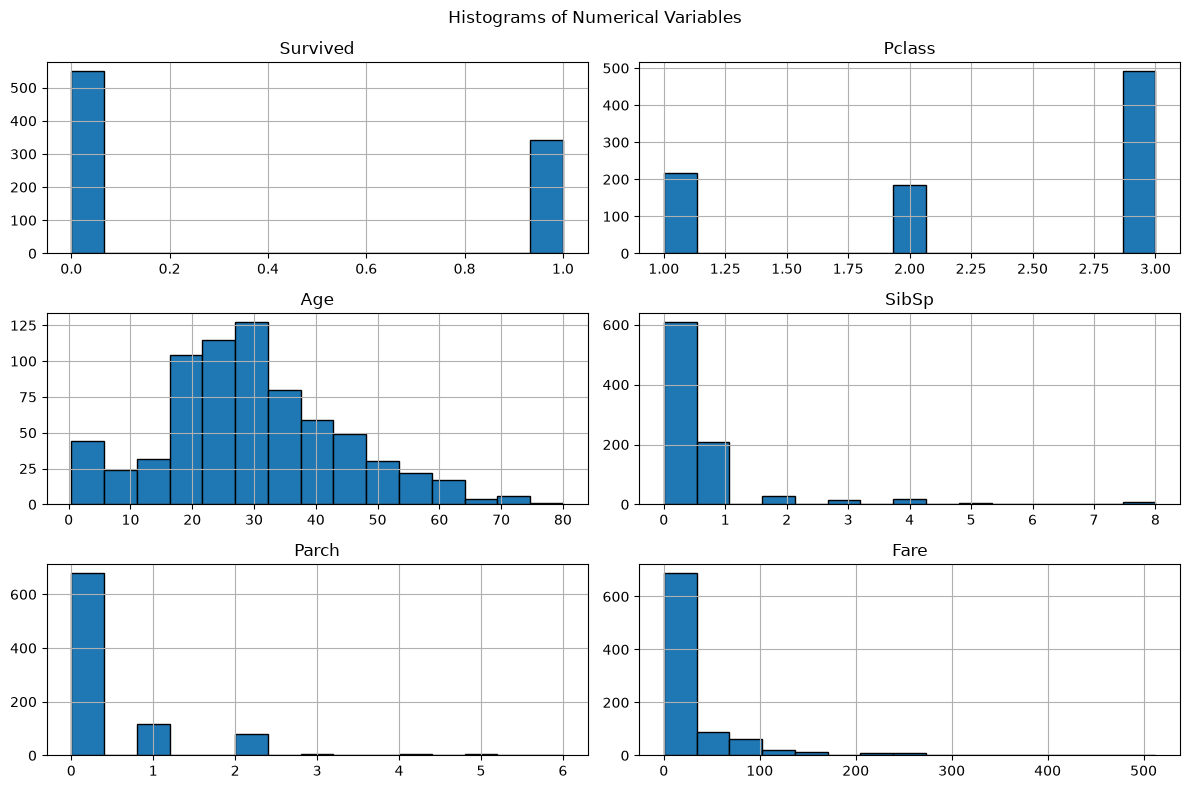

In [5]:
numeric_df.hist(figsize=(12, 8), bins=15, edgecolor="black")
plt.suptitle("Histograms of Numerical Variables")
plt.tight_layout()
plt.show()

### 5. Correlation Analysis — Heatmap
Compute the Pearson correlation matrix and render it as an annotated heatmap using a diverging colour palette. High absolute values indicate strong linear relationships between features.

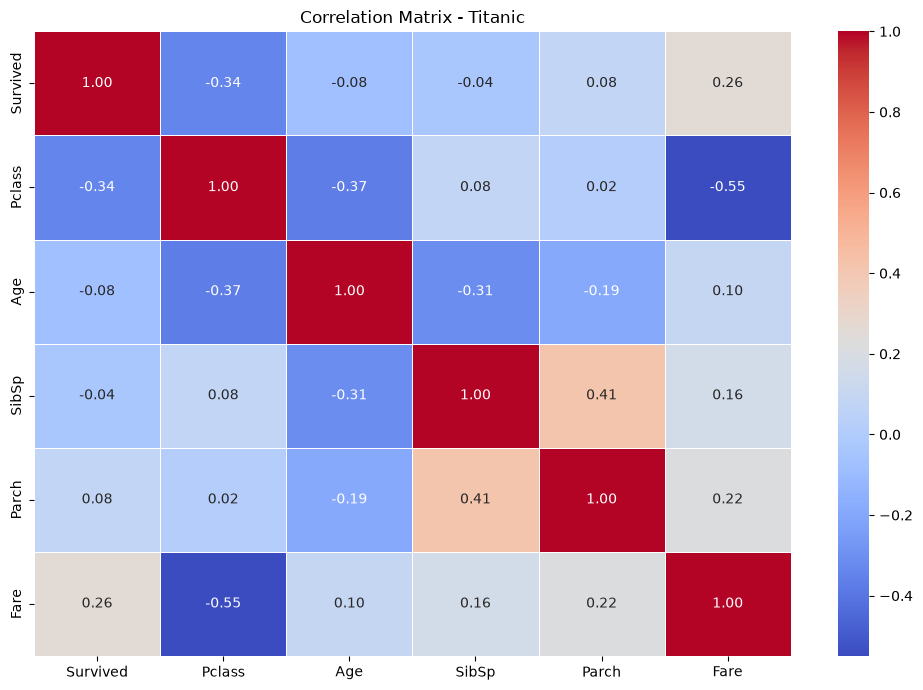

In [6]:
corr = numeric_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix - Titanic")
plt.tight_layout()
plt.show()

### 6. Top Correlated Variable Pairs
Extract and rank the upper triangle of the correlation matrix to surface the most strongly correlated feature pairs — useful for feature selection and multicollinearity awareness.

In [7]:
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack()
print("Top correlated variable pairs:")
print(pairs.sort_values(key=abs, ascending=False).head(10))

Top correlated variable pairs:
Pclass    Fare     -0.549500
SibSp     Parch     0.414838
Pclass    Age      -0.369226
Survived  Pclass   -0.338481
Age       SibSp    -0.308247
Survived  Fare      0.257307
Parch     Fare      0.216225
Age       Parch    -0.189119
SibSp     Fare      0.159651
Age       Fare      0.096067
dtype: float64
